In [41]:
%load_ext autoreload
%autoreload 2
import xdas
import os, subprocess
from obspy import read, UTCDateTime
from utils.utils_det import plot_DAS, plot_picks, associate_DAS, plot_phasenet_das
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sys

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# APPLY ON DAS RECORDS

In [17]:
import matplotlib.cm as cmx
import matplotlib.colors as colors
#from matplotlib.cm import get_cmap
import matplotlib.ticker as mticker
import matplotlib.pyplot as plt
import matplotlib
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.ticker as ticker

plt.rcParams['axes.spines.bottom'] = True
plt.rcParams['axes.spines.left'] = True
plt.rcParams['axes.spines.right'] = True
plt.rcParams['axes.spines.top'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['axes.grid.axis'] = 'both'
plt.rcParams['grid.color'] = 'darkgrey'
plt.rcParams['grid.linewidth'] = 0.5
plt.rcParams['axes.axisbelow'] = False
plt.rcParams['axes.linewidth'] = 1.5
plt.rcParams['axes.ymargin'] = 0.1
# -- Ticks and tick labels --
plt.rcParams['axes.edgecolor'] = 'k'
plt.rcParams['xtick.color'] = 'k'
plt.rcParams['ytick.color'] = 'k'
plt.rcParams['xtick.major.width'] = 2
plt.rcParams['ytick.major.width'] = 2
plt.rcParams['xtick.major.size'] = 3
plt.rcParams['ytick.major.size'] = 3
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
# -- Fonts --
plt.rcParams['font.size'] = 12
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Verdana']
plt.rcParams['text.color'] = 'k'
plt.rcParams['axes.labelcolor'] = 'k'
plt.rcParams['axes.labelsize'] = 12
# -- Saving Options --
plt.rcParams['savefig.bbox'] = 'tight'
plt.rcParams['savefig.dpi'] = 100
plt.rcParams['savefig.transparent'] = False
# -- Plot Styles --
plt.rcParams['lines.linewidth'] = 1
plt.rcParams["lines.markersize"] = 3
plt.rcParams["lines.markeredgewidth"] = 1
plt.rcParams["figure.dpi"] = 100


66.26003


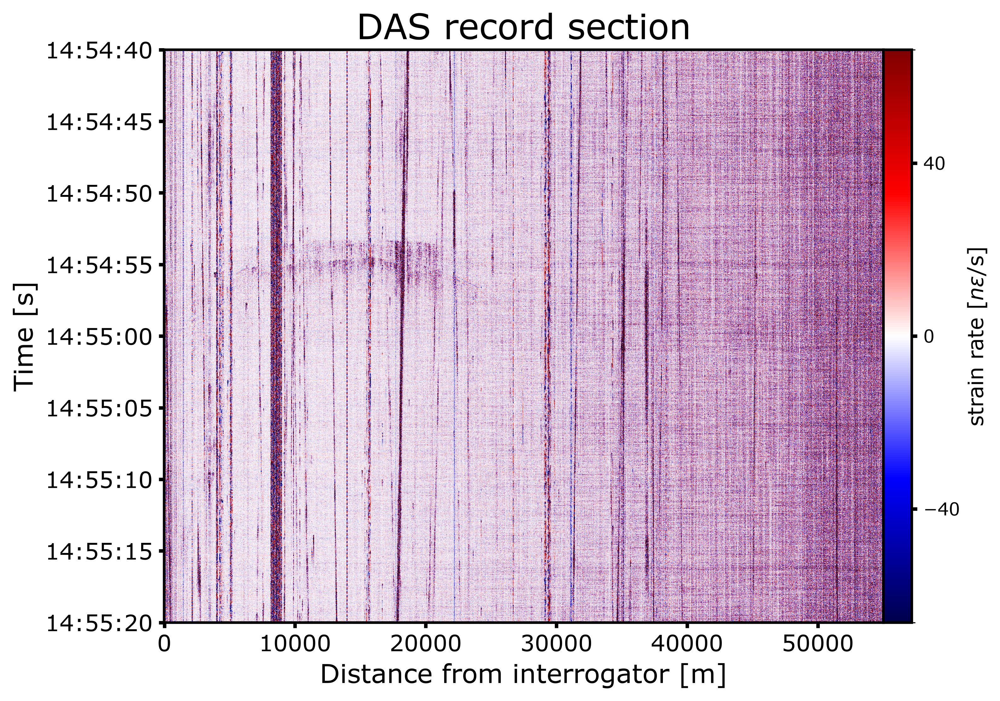

In [36]:
#da = xdas.open_dataarray('traces_DAS/SR_DS_CH2_2026-04-12_13-24-54_UTC.nc')
fname = 'SR_DS_CH2_2025-12-25_14-54-52_UTC.nc'
da = xdas.open_dataarray(f"EQNet/scripts/dataset/{fname}")
da = xdas.signal.detrend(da,'constant')
da = da.sel(time = slice('2025-12-25 14:54:40', '2025-12-25 14:55:20'))
#da = da.sel(time = slice('2026-04-12 13:24:55', '2026-04-12 13:25:10'))
plot_DAS(da, sat = 100)

# APPLY ORIGINAL PHASENET-DAS

In [37]:
os.chdir('EQNet/scripts')

result = subprocess.run(
    [sys.executable, "run_phasenet_das_original_model.py"],
    cwd=os.getcwd(),
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Return code:", result.returncode)

os.chdir('../../')


Running with 0 GPU
python ../predict.py --model phasenet_das --format h5 --data_list results\phasenet_das_original\dataset\h5_list.txt --batch_size 1 --result_path results\phasenet_das_original\dataset --dataset=das --min_prob=0.8 --plot_figure --device=cpu
Not using distributed mode
Namespace(model='phasenet_das', resume='', backbone='unet', phases=['P', 'S'], device='cpu', workers=0, batch_size=1, use_deterministic_algorithms=False, amp=False, world_size=1, dist_url='env://', data_path='./', data_list='results\\phasenet_das_original\\dataset\\h5_list.txt', hdf5_file=None, prefix='', format='h5', dataset='das', result_path='results\\phasenet_das_original\\dataset', plot_figure=True, min_prob=0.8, add_polarity=False, add_event=False, sampling_rate=100.0, highpass_filter=0.0, response_path=None, response_xml=None, subdir_level=0, cut_patch=False, nt=20480, nx=5120, resample_time=False, resample_space=False, system=None, location=None, skip_existing=False, dataset_DAS='original', distrib

c:\Users\franc\Documents\DAS_workflow_2D_github\utils\utils_det.py:565: FutureWarning: coordinate 'distance' has no declared sampling interval; inferred 20.0 (accepting jitter up to tolerance=2.9103830456733704e-11). This implicit inference is deprecated and will raise in a future release; make the coordinate regular with `da['distance'] = da['distance'].to_regular(tolerance=...)`, or open the files with a tolerance
  picks.insert(5,"index_plot",xr["distance"].values[0] + picks["channel_index"].values * xdas.get_sampling_interval(xr, dim = 'distance'))


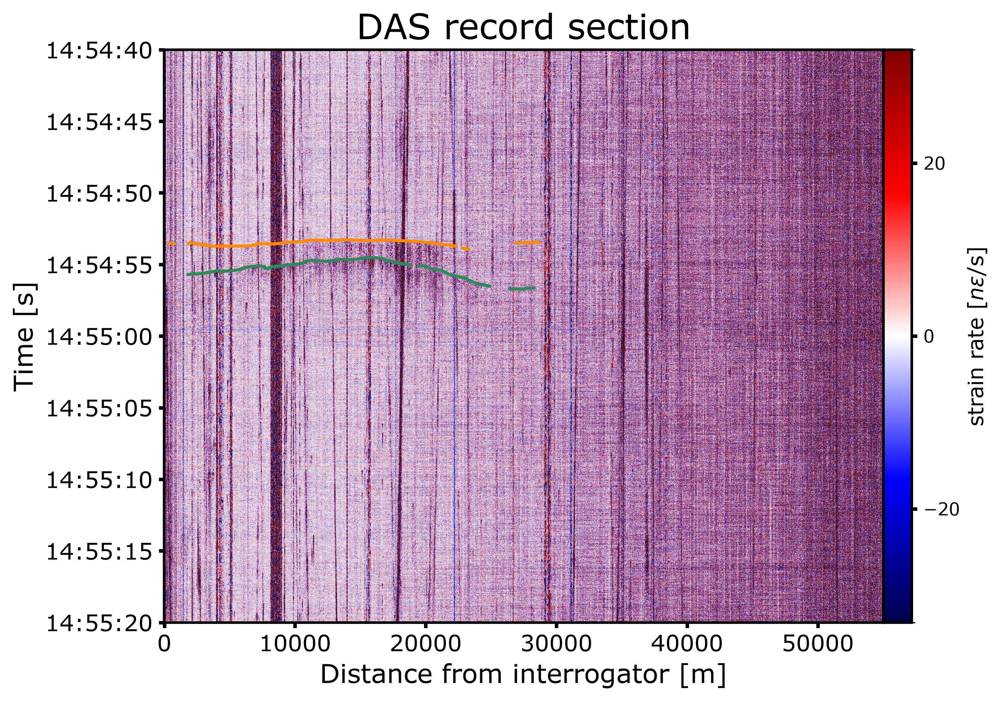

In [38]:
pick_PN_DAS = pd.read_csv(f"EQNet/scripts/results/phasenet_das_original/dataset/picks_phasenet_das/{fname}.csv")
plot_phasenet_das(da, pick_PN_DAS, time_deci = 2, space_deci = 1, sat = 200, size = 0.5)


# PHASE ASSOCIATION

Associating 4687 picks with 1 CPUs
.

c:\Users\franc\anaconda3\envs\test\Lib\site-packages\gamma\seismic_ops.py:302: OptimizeWarning: Unknown solver options: iprint
  opt = scipy.optimize.minimize(


Associated events with 1151 P and 1225 S picks


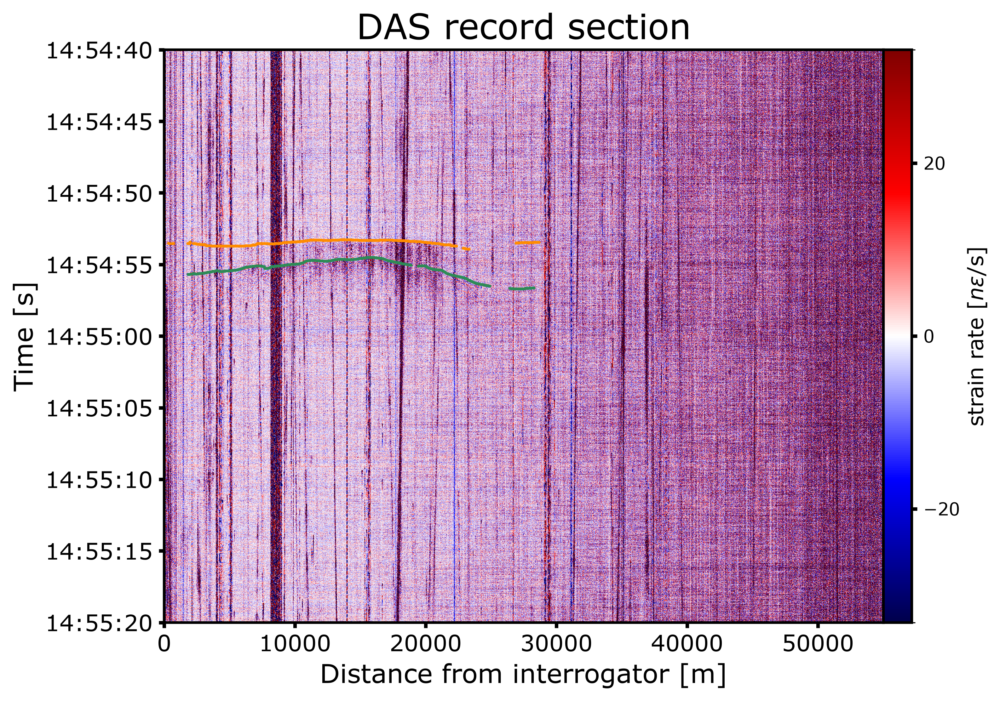

In [42]:

gamma_folder = 'results/gamma_PN_DAS_picks'
os.makedirs(gamma_folder, exist_ok = True)

associate_DAS(da,
          pick_PN_DAS, 
          gamma_picks = gamma_folder, 
          prob_thresh = 0.2,
          plot = True)

# APPLY LOCAL PHASENET-DAS

In [46]:
os.chdir('EQNet/scripts')

result = subprocess.run(
    [sys.executable, "run_phasenet_das_local_model.py"],
    cwd=os.getcwd(),
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Return code:", result.returncode)

os.chdir('../../')


Running with 0 GPU
python ../predict.py --model phasenet_das --dataset_DAS=irpinia_v2 --format h5 --data_list results\phasenet_das_local\dataset\h5_list.txt --batch_size 1 --result_path results\phasenet_das_local\dataset --dataset=das --min_prob=0.3 --plot_figure --device=cpu
Not using distributed mode
Namespace(model='phasenet_das', resume='', backbone='unet', phases=['P', 'S'], device='cpu', workers=0, batch_size=1, use_deterministic_algorithms=False, amp=False, world_size=1, dist_url='env://', data_path='./', data_list='results\\phasenet_das_local\\dataset\\h5_list.txt', hdf5_file=None, prefix='', format='h5', dataset='das', result_path='results\\phasenet_das_local\\dataset', plot_figure=True, min_prob=0.3, add_polarity=False, add_event=False, sampling_rate=100.0, highpass_filter=0.0, response_path=None, response_xml=None, subdir_level=0, cut_patch=False, nt=20480, nx=5120, resample_time=False, resample_space=False, system=None, location=None, skip_existing=False, dataset_DAS='irpin

c:\Users\franc\Documents\DAS_workflow_2D_github\utils\utils_det.py:565: FutureWarning: coordinate 'distance' has no declared sampling interval; inferred 20.0 (accepting jitter up to tolerance=2.9103830456733704e-11). This implicit inference is deprecated and will raise in a future release; make the coordinate regular with `da['distance'] = da['distance'].to_regular(tolerance=...)`, or open the files with a tolerance
  picks.insert(5,"index_plot",xr["distance"].values[0] + picks["channel_index"].values * xdas.get_sampling_interval(xr, dim = 'distance'))


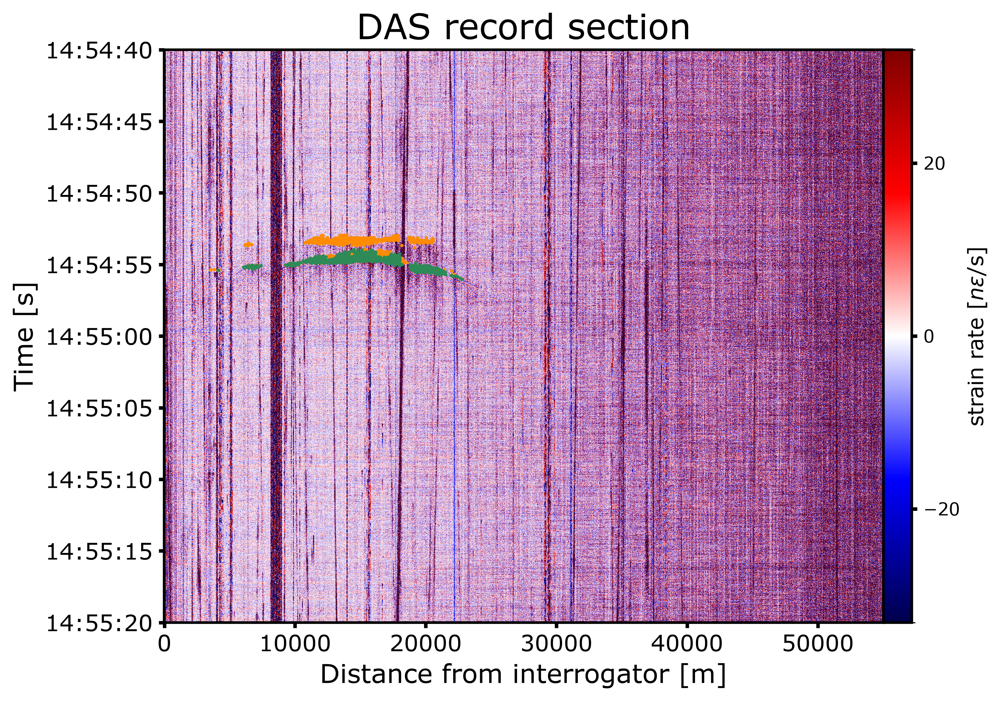

In [47]:
pick_PN_DAS = pd.read_csv(f"EQNet/scripts/results/phasenet_das_local/dataset/picks_phasenet_das/{fname}.csv")
plot_phasenet_das(da, pick_PN_DAS, time_deci = 2, space_deci = 1, sat = 200, size = 0.5)


Associating 4772 picks with 1 CPUs
.

c:\Users\franc\anaconda3\envs\test\Lib\site-packages\gamma\seismic_ops.py:302: OptimizeWarning: Unknown solver options: iprint
  opt = scipy.optimize.minimize(


Associated events with 482 P and 606 S picks


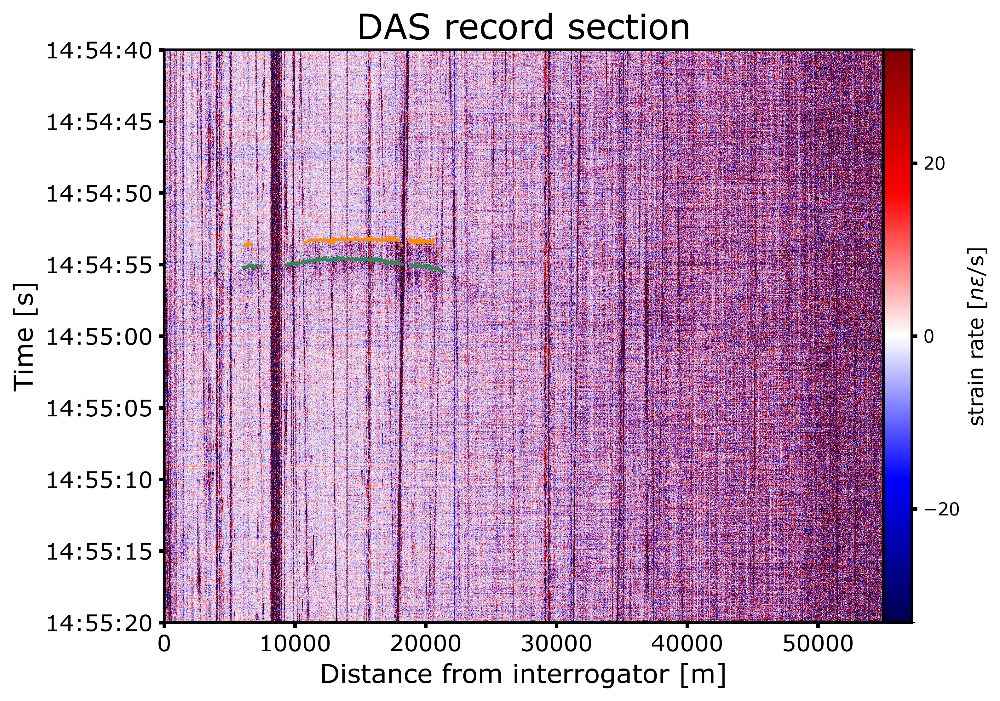

In [49]:
gamma_folder = 'results/gamma_PN_DAS_local_picks'
os.makedirs(gamma_folder, exist_ok = True)

associate_DAS(da,
          pick_PN_DAS, 
          gamma_picks = gamma_folder, 
          prob_thresh = 0.3,
          plot = True)

# APPLY PHASENET-DAS FROM TRANSFER LEARNING

In [50]:
os.chdir('EQNet/scripts')

result = subprocess.run(
    [sys.executable, "run_phasenet_das_transfer_learning.py"],
    cwd=os.getcwd(),
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)
print("Return code:", result.returncode)

os.chdir('../../')


Running with 0 GPU
python ../predict.py --model phasenet_das --dataset_DAS=transfer_learning --format h5 --data_list results\phasenet_das_transfer\dataset\h5_list.txt --batch_size 1 --result_path results\phasenet_das_transfer\dataset --dataset=das --min_prob=0.3 --plot_figure --device=cpu
Not using distributed mode
Namespace(model='phasenet_das', resume='', backbone='unet', phases=['P', 'S'], device='cpu', workers=0, batch_size=1, use_deterministic_algorithms=False, amp=False, world_size=1, dist_url='env://', data_path='./', data_list='results\\phasenet_das_transfer\\dataset\\h5_list.txt', hdf5_file=None, prefix='', format='h5', dataset='das', result_path='results\\phasenet_das_transfer\\dataset', plot_figure=True, min_prob=0.3, add_polarity=False, add_event=False, sampling_rate=100.0, highpass_filter=0.0, response_path=None, response_xml=None, subdir_level=0, cut_patch=False, nt=20480, nx=5120, resample_time=False, resample_space=False, system=None, location=None, skip_existing=False,

c:\Users\franc\Documents\DAS_workflow_2D_github\utils\utils_det.py:565: FutureWarning: coordinate 'distance' has no declared sampling interval; inferred 20.0 (accepting jitter up to tolerance=2.9103830456733704e-11). This implicit inference is deprecated and will raise in a future release; make the coordinate regular with `da['distance'] = da['distance'].to_regular(tolerance=...)`, or open the files with a tolerance
  picks.insert(5,"index_plot",xr["distance"].values[0] + picks["channel_index"].values * xdas.get_sampling_interval(xr, dim = 'distance'))


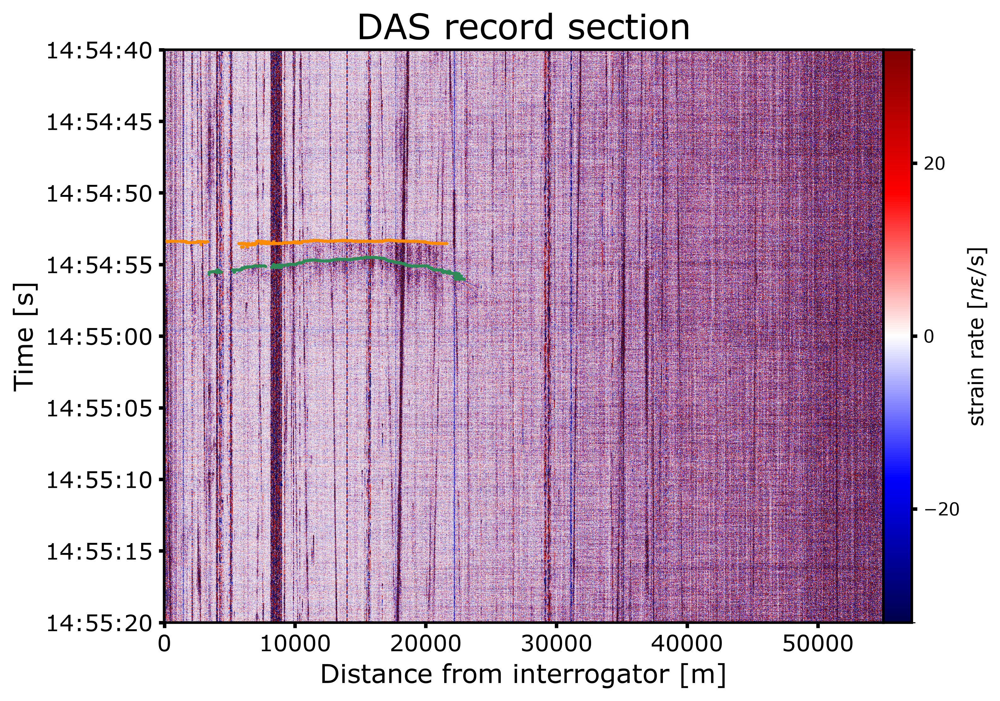

In [51]:
pick_PN_DAS = pd.read_csv(f"EQNet/scripts/results/phasenet_das_transfer/dataset/picks_phasenet_das/{fname}.csv")
plot_phasenet_das(da, pick_PN_DAS, time_deci = 2, space_deci = 1, sat = 200, size = 0.5)

Associating 5748 picks with 1 CPUs
.

c:\Users\franc\anaconda3\envs\test\Lib\site-packages\gamma\seismic_ops.py:302: OptimizeWarning: Unknown solver options: iprint
  opt = scipy.optimize.minimize(


Associated events with 954 P and 917 S picks


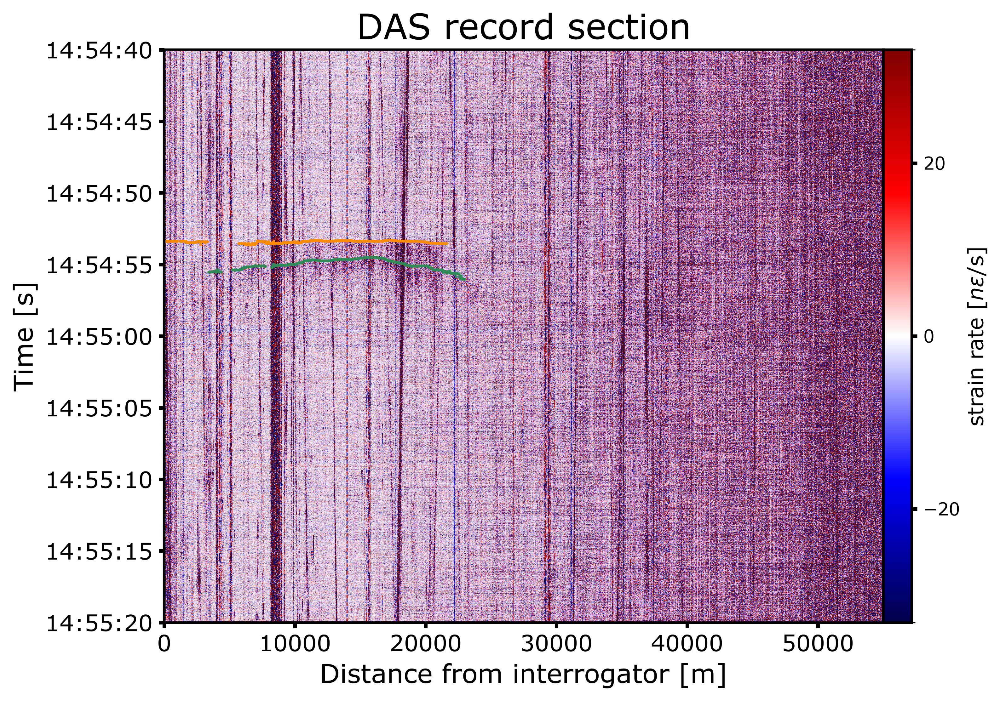

In [52]:
gamma_folder = 'results/gamma_PN_DAS_transfer_picks'
os.makedirs(gamma_folder, exist_ok = True)

associate_DAS(da,
          pick_PN_DAS, 
          gamma_picks = gamma_folder, 
          prob_thresh = 0.3,
          plot = True)